# Intensity-Modulated photocurrent Spectroscopy simulation

In [1]:
import os, sys
try:
    import pySIMsalabim as sim
except ImportError: # add parent directory to sys.path if pySIMsalabim is not installed
    sys.path.append('..')
    import pySIMsalabim as sim
from pySIMsalabim.experiments.imps import *

# Use the default input files shipped with the pySIMsalabim tests (pySIMsalabim/tests/sim_inputs/default):
# check that they match the SIMsalabim version and copy them into SIMsalabim/SimSS and SIMsalabim/ZimT
sys.path.append(os.path.join('..', 'pySIMsalabim', 'tests'))
from sim_inputs_setup import prepare_test_inputs, cleanup_test_inputs
prepare_test_inputs(convert=False)

Test inputs for SimSS: version matches SIMsalabim 5.37
Test inputs for ZimT: version matches SIMsalabim 5.37
Copying the SimSS test inputs to /home/lecorre/Desktop/pySIMsalabim/SIMsalabim/SimSS
Copying the ZimT test inputs to /home/lecorre/Desktop/pySIMsalabim/SIMsalabim/ZimT


### Setup the simulation

In [2]:
# Set the path to the simulation setup file
cwd = os.path.abspath('..')
session_path = os.path.join(cwd, 'SIMsalabim','ZimT')
zimt_device_parameters = os.path.join(session_path, 'simulation_setup_test.txt')

# Set the impedance simulation parameters
tVG_name = os.path.join(session_path,'tVG.txt')
f_min = 1e-1
f_max = 5e6
f_steps = 20
V = 0.0
G_frac = 1
GStep = 0.05
# Run the IMPS simulation
ret, mess = run_IMPS_simu(zimt_device_parameters, session_path, f_min, f_max, f_steps, V, G_frac, GStep, run_mode=False, tVG_name = tVG_name, output_file = 'freqY.dat', tj_name = 'tj.dat')

### Plot results

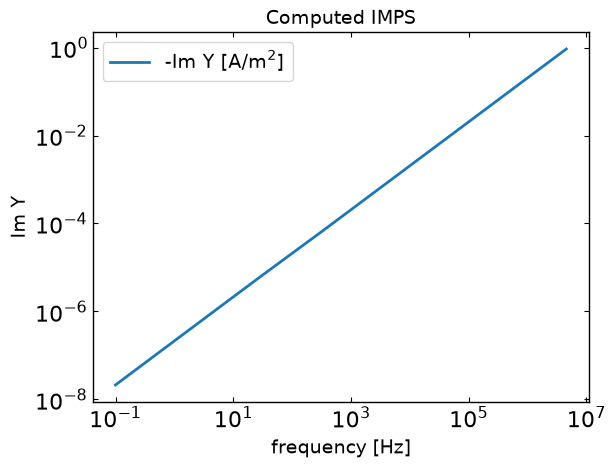

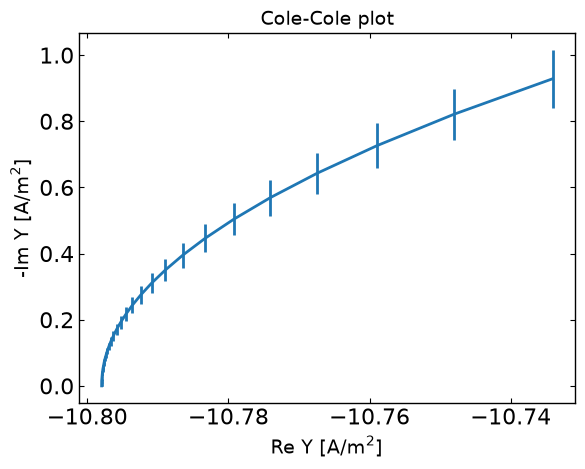

In [3]:
plot_IMPS(session_path, output_file='freqY.dat')

In [4]:
# Clean up the output files (comment out if you want to keep the output files)
sim.clean_all_output(session_path)
sim.clean_up_output('freqY',session_path)
sim.delete_folders('tmp',session_path)

# Remove the test input files copied into the SIMsalabim folder
cleanup_test_inputs()